# Reading a scanned table: Clairic vs TypeLLM

The first 20 rows of a scanned stock count, with no text layer: a SKU, an item and a count per row. Each API reads the table three times, and every cell is scored against a hand-typed ground truth:

- **TypeLLM API**: one array of objects, each row a `{sku, item, count}`.
- **Clairic** (Cloudflare Workers AI, `@cf/cloudflare/clairic`, preview). Its fields have no array of objects, so it is asked two ways:
  - **three lists**, one a column: SKUs and items as `text`, counts as `number`;
  - **one list of rows**, each its whole line as `text`, split here into SKU (the first word), count (the last) and item (the words between).

The ground truth is `data/stock_count_truth.csv`, typed from the page.

In [1]:
%pip install -q "typellm>=0.7.2" pymupdf matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


## Keys

A TypeLLM key from the [API keys](https://typellm.ai/dashboard/keys) page, and a Cloudflare account ID with an API token that can run Workers AI.

In [2]:
import os

# Paste your keys here, or set them as environment variables.
TYPELLM_API_KEY = os.environ.get("TYPELLM_API_KEY", "")  # https://typellm.ai/dashboard/keys
CLOUDFLARE_ACCOUNT_ID = os.environ.get("CLOUDFLARE_ACCOUNT_ID", "")
CLOUDFLARE_API_TOKEN = os.environ.get("CLOUDFLARE_API_TOKEN", "")  # a token that can run Workers AI

## The table

The column headers and the first 20 rows of page 1, cut from a 200 dpi render.

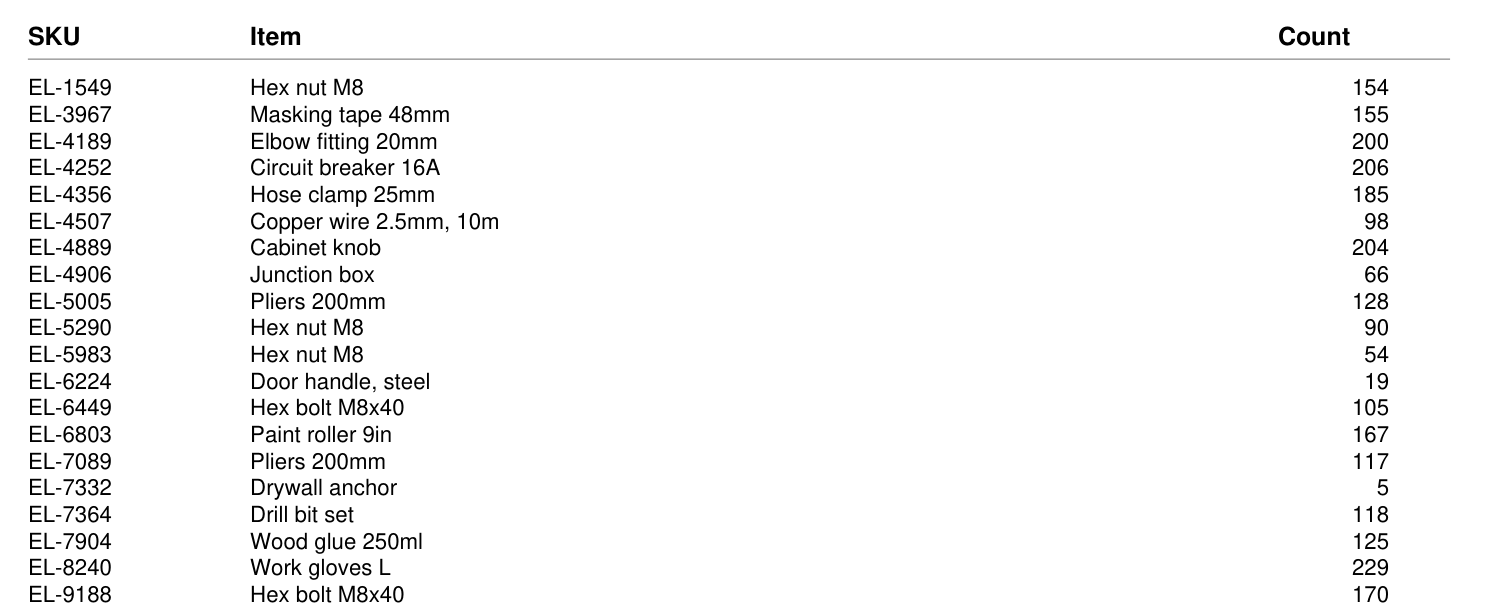

In [3]:
import base64, difflib, json, re, urllib.request
from concurrent.futures import ThreadPoolExecutor

import pandas as pd
import pymupdf
from IPython.display import Image, display
from typellm import TypeLLMClient

ROWS, RUNS = 20, 3
HEADER_TOP, FIRST_ROW, ROW_PITCH = 68, 99.0, 9.594  # PDF points: the column headers, row 1's centre, row spacing

RAW = "https://raw.githubusercontent.com/TypeLLM/TypeLLM/main/"
for path, url in {"data/stock_count.pdf": RAW + "examples/notebooks/data/stock_count.pdf",
                  "data/stock_count_truth.csv": RAW + "evals/clairic_stock_count/data/stock_count_truth.csv"}.items():
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(url, path)

page = pymupdf.open("data/stock_count.pdf")[0]
image = page.get_pixmap(dpi=200, clip=pymupdf.Rect(40, HEADER_TOP, 575, FIRST_ROW + (ROWS - 0.5) * ROW_PITCH)).tobytes("png")
truth = pd.read_csv("data/stock_count_truth.csv")
assert len(truth) == ROWS
display(Image(image, width=700))

## The calls

The same context for every call. TypeLLM answers at temperature 0; Clairic has no sampling setting.

In [4]:
CONTEXT = "A scanned stock count table."
COLUMNS = {"sku": "SKU", "item": "item name", "count": "count"}
INSTRUCTIONS = {name: f"The {what} of every row of the stock count table, in order." for name, what in COLUMNS.items()}

typellm = TypeLLMClient(api_key=TYPELLM_API_KEY, timeout=90)


def ask_typellm(png):
    rows = {"type": "array", "items": {"type": "object", "properties": {
                "sku": {"type": "string"}, "item": {"type": "string"}, "count": {"type": "integer"}}},
            "instructions": "Every row of the stock count table, in order."}
    rows = typellm.generate(context=CONTEXT, images=[png], questions={"rows": rows}).result["rows"]
    return {name: [row[name] for row in rows] for name in COLUMNS}


def clairic(png, fields):
    body = {"state": CONTEXT, "images": ["data:image/png;base64," + base64.b64encode(png).decode()], "fields": fields}
    request = urllib.request.Request(
        f"https://api.cloudflare.com/client/v4/accounts/{CLOUDFLARE_ACCOUNT_ID}/ai/run/@cf/cloudflare/clairic",
        data=json.dumps(body).encode(), method="POST",
        headers={"Authorization": f"Bearer {CLOUDFLARE_API_TOKEN}", "Content-Type": "application/json"})
    with urllib.request.urlopen(request, timeout=180) as response:
        return json.load(response)["result"]["answers"]


def ask_clairic_lists(png):
    fields = {name: {"type": "list", "items": "number" if name == "count" else "text",
                     "instructions": INSTRUCTIONS[name]} for name in COLUMNS}
    answers = clairic(png, fields)
    return {name: answers[name]["value"] for name in COLUMNS}


LINE = re.compile(r"^\s*(\S+)\s+(.*?)\s+(\d+)\s*$")  # SKU, item, count


def ask_clairic_rows(png):
    fields = {"rows": {"type": "list", "items": "text",
                       "instructions": "Every row of the stock count table, in order, each as its whole line: SKU, item and count."}}
    lines = clairic(png, fields)["rows"]["value"]
    # A line that does not split into the three is kept whole as its SKU, and scores nothing.
    rows = [(m[1], m[2], int(m[3])) if (m := LINE.match(line)) else (line, None, None) for line in lines]
    return {name: [row[i] for row in rows] for i, name in enumerate(COLUMNS)}


SYSTEMS = {"TypeLLM": ask_typellm, "Clairic, three lists": ask_clairic_lists, "Clairic, one list of rows": ask_clairic_rows}

## Scoring

Each column is scored on its own: its cells are matched to the truth in order (the longest common subsequence), so one missed cell costs that cell, not every cell after it. A **whole row** is right only when its SKU, item and count all are; Clairic's three lists are put together into rows by position, as a caller would have to. Accuracy is right cells, or rows, over the 20 rows: an extra one scores nothing, and a missing one counts as wrong.

In [5]:
def matched(expected, got):
    return sum(block.size for block in difflib.SequenceMatcher(None, expected, got, autojunk=False).get_matching_blocks())


def tidy(value):
    if isinstance(value, float) and value.is_integer():
        return int(value)
    return value.strip() if isinstance(value, str) else value


def run(system, attempt):
    try:
        answer, error = SYSTEMS[system](image), None
    except Exception as exc:  # a failed call scores zero, and says why
        answer, error = {name: [] for name in COLUMNS}, f"{type(exc).__name__}: {exc}"
    answer = {name: [tidy(v) for v in values] for name, values in answer.items()}
    return {"system": system, "run": attempt, "error": error,
            **{name: matched(list(truth[name]), answer[name]) / ROWS for name in COLUMNS},
            "row": matched(list(truth.itertuples(index=False, name=None)), list(zip(*answer.values()))) / ROWS,
            **{f"{name} returned": len(answer[name]) for name in COLUMNS}, "answer": answer}

In [6]:
with ThreadPoolExecutor(3) as pool:
    runs = list(pool.map(lambda job: run(*job), [(system, n) for n in range(1, RUNS + 1) for system in SYSTEMS]))

os.makedirs("outputs", exist_ok=True)
with open("outputs/runs.json", "w") as f:
    json.dump(runs, f, indent=1)
results = pd.DataFrame(runs).drop(columns="answer")
print(f"{len(results)} calls, {results.error.notna().sum()} failed")

9 calls, 0 failed


## Results

Every call, with the cells each column returned:

In [7]:
ACCURACY = [*COLUMNS, "row"]
RETURNED = [f"{name} returned" for name in COLUMNS]
(results.sort_values(["system", "run"], key=lambda col: col.map(list(SYSTEMS).index) if col.name == "system" else col)[["system", "run", *ACCURACY, *RETURNED]]
 .style.format({c: "{:.0%}" for c in ACCURACY}).hide(axis="index"))

system,run,sku,item,count,row,sku returned,item returned,count returned
TypeLLM,1,100%,100%,100%,100%,20,20,20
TypeLLM,2,100%,100%,100%,100%,20,20,20
TypeLLM,3,100%,100%,100%,100%,20,20,20
"Clairic, three lists",1,5%,5%,90%,5%,1,2,20
"Clairic, three lists",2,5%,5%,90%,5%,1,2,20
"Clairic, three lists",3,5%,5%,90%,5%,1,2,20
"Clairic, one list of rows",1,5%,0%,0%,0%,2,2,2
"Clairic, one list of rows",2,5%,0%,0%,0%,2,2,2
"Clairic, one list of rows",3,5%,0%,0%,0%,2,2,2


The mean of the three runs:

In [8]:
summary = results.groupby("system", sort=False)[ACCURACY].mean()
summary.style.format("{:.0%}")

,sku,item,count,row
system,,,,
TypeLLM,100%,100%,100%,100%
"Clairic, three lists",5%,5%,90%,5%
"Clairic, one list of rows",5%,0%,0%,0%


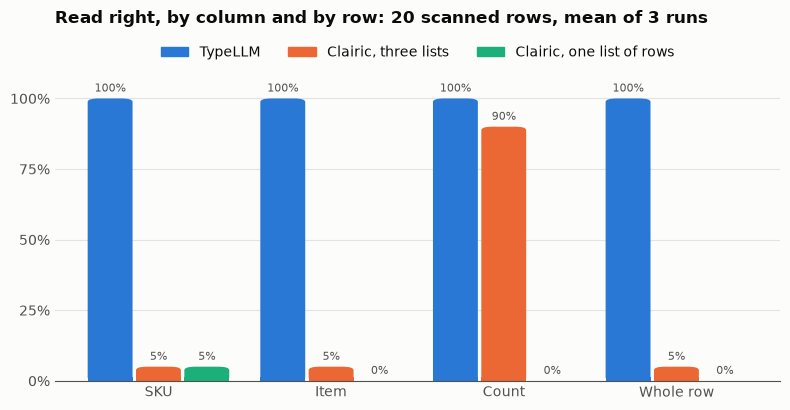

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

# Colors by system, in a fixed order; text stays in ink colors.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = dict(zip(SYSTEMS, ["#2a78d6", "#eb6834", "#1baf7a"]))
LABELS = {"sku": "SKU", "item": "Item", "count": "Count", "row": "Whole row"}


def bar(ax, x, width, height, color):
    """A bar with a rounded top, square on the baseline."""
    if height <= 0:
        return
    radius = min(1.2, height)
    ax.add_patch(FancyBboxPatch((x, 0), width, height, boxstyle=f"round,pad=0,rounding_size={width * 0.25}",
                                mutation_aspect=radius / (width * 0.25), facecolor=color, edgecolor="none"))
    ax.add_patch(Rectangle((x, 0), width, min(height, radius), facecolor=color, edgecolor="none"))


fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
width, step = 0.26, 0.28  # 0.02 of the surface between bars
for i, system in enumerate(SYSTEMS):
    for j, column in enumerate(ACCURACY):
        value = summary.loc[system, column] * 100
        x = j + (i - 1) * step - width / 2
        bar(ax, x, width, value, COLORS[system])
        ax.text(x + width / 2, value + 1.5, f"{value:.0f}%", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(range(len(ACCURACY)), [LABELS[c] for c in ACCURACY])
ax.set_xlim(-0.6, len(ACCURACY) - 0.4)
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 25), [f"{v}%" for v in range(0, 101, 25)])
ax.set_facecolor(SURFACE)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_2, length=0, labelsize=10)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(INK_2)
ax.legend([Rectangle((0, 0), 1, 1, color=COLORS[s]) for s in SYSTEMS], SYSTEMS, loc="upper center", ncol=3,
          frameon=False, fontsize=10, labelcolor=INK, bbox_to_anchor=(0.5, 1.12))
ax.set_title(f"Read right, by column and by row: {ROWS} scanned rows, mean of {RUNS} runs",
             loc="left", fontsize=12, color=INK, fontweight="bold", pad=34)
fig.tight_layout()
fig.savefig("outputs/accuracy.png", dpi=160, bbox_inches="tight", facecolor=SURFACE)
plt.show()

Each API gave the same answer in all three runs:

- **TypeLLM read every row right**: 20 rows, each with its SKU, item and count, and no row more.
- **Clairic, three lists**, read one SKU and one item, the first of each; its second item was `"Masking 44mm El 222"`, and the lists stopped there. It read 18 of the 20 counts, misreading 5 as 1.1 and 118 as 11.8. With one SKU, only the first row could be put together.
- **Clairic, one list of rows**, returned two lines, `"EL-1549"` and `"Hex nut8"`, neither a whole row: the first SKU is all that scores.

## What came back

Each system's first run, next to the truth (— where a column ended):

In [10]:
first = {r["system"]: r["answer"] for r in runs if r["run"] == 1}
side_by_side = truth.copy()
for system, answer in first.items():
    for name in COLUMNS:
        values = answer[name]
        side_by_side[f"{system} {name}"] = [values[i] if i < len(values) else "—" for i in range(ROWS)]
side_by_side

,sku,item,count,TypeLLM sku,TypeLLM item,TypeLLM count,"Clairic, three lists sku","Clairic, three lists item","Clairic, three lists count","Clairic, one list of rows sku","Clairic, one list of rows item","Clairic, one list of rows count"
0,EL-1549,Hex nut M8,154,EL-1549,Hex nut M8,154,EL-1549,Hex nut M8,154.0,EL-1549,NaN,NaN
1,EL-3967,Masking tape 48mm,155,EL-3967,Masking tape 48mm,155,—,Masking 44mm El 222,155.0,Hex nut8,NaN,NaN
2,EL-4189,Elbow fitting 20mm,200,EL-4189,Elbow fitting 20mm,200,—,—,200.0,—,—,—
3,EL-4252,Circuit breaker 16A,206,EL-4252,Circuit breaker 16A,206,—,—,206.0,—,—,—
4,EL-4356,Hose clamp 25mm,185,EL-4356,Hose clamp 25mm,185,—,—,185.0,—,—,—
5,EL-4507,"Copper wire 2.5mm, 10m",98,EL-4507,"Copper wire 2.5mm, 10m",98,—,—,98.0,—,—,—
6,EL-4889,Cabinet knob,204,EL-4889,Cabinet knob,204,—,—,204.0,—,—,—
7,EL-4906,Junction box,66,EL-4906,Junction box,66,—,—,66.0,—,—,—
8,EL-5005,Pliers 200mm,128,EL-5005,Pliers 200mm,128,—,—,128.0,—,—,—
9,EL-5290,Hex nut M8,90,EL-5290,Hex nut M8,90,—,—,90.0,—,—,—
